In [19]:
import geopandas as gpd
import pandas as pd
from matplotlib import pyplot as plt
from tqdm import tqdm
from pathlib import Path

In [6]:
def get_data(folder, file_name, crs):
    """Takes a folder, shapefile and crs and returns the geodataframe"""

    gdf = gpd.read_file(f'data/raw/{folder}/{file_name}')
    gdf = gdf.to_crs(crs)
    return gdf

In [14]:
def output_data(folder, data_type, gdf):
    """Takes an output folder and a filename and outputs a geodataframe to shapefile"""

    output_folder = folder + data_type
    Path(output_folder).mkdir(parents=True, exist_ok=True)
    gdf.to_file(f'{output_folder}/{data_type}.shp')

In [16]:
def chunk_intersection(gdf, boundary):
    """"""

    boundary = boundary.copy().simplify(5)
    chunk_size = 10000
    results = []

    for start in tqdm(range(0, len(gdf), chunk_size)):
        chunk = gdf.iloc[start:start + chunk_size].copy()
        chunk = gpd.clip(chunk, boundary)
        results.append(chunk)

    results = pd.concat(results)

    return results


In [7]:
# Import raw data

folder = 'greater-london-260304-free.shp'
crs = 27700

roads_gdf = get_data(folder, file_name='gis_osm_roads_free_1.shp', crs=crs)
water_gdf = get_data(folder, file_name='gis_osm_water_a_free_1.shp', crs=crs)
landuse_gdf = get_data(folder, file_name='gis_osm_landuse_a_free_1.shp', crs=crs)

greater_london = gpd.read_file('data/raw/gla/London_GLA_Boundary.shp')

In [10]:
# Extract parks from landuse
parks_gdf = landuse_gdf[landuse_gdf.fclass == 'park']

In [11]:
# Get rid of small roads
roads_gdf = roads_gdf[~roads_gdf['fclass'].isin(['footway', 'service', 'cycleway'])]

In [23]:
# Get only shapes that are in london
roads_london_gdf = chunk_intersection(roads_gdf, greater_london)
water_london_gdf = chunk_intersection(water_gdf, greater_london)
parks_london_gdf = chunk_intersection(parks_gdf, greater_london)

100%|██████████| 1/1 [00:00<00:00,  1.05it/s]


In [26]:
# Write london shapefiles to file
folder = 'data/intermediary/'

output_data(folder, 'roads', roads_london_gdf)
output_data(folder, 'water', water_london_gdf)
output_data(folder, 'parks', parks_london_gdf)

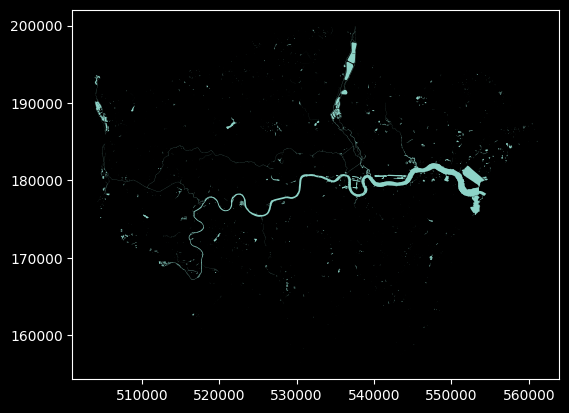

In [27]:
water_london_gdf.plot()
plt.show()